In [3]:
import traffic
import pandas as pd
import numpy as np
import sklearn
import plotly
import pyopensky

print("环境配置成功")

环境配置成功


In [1]:
#连接opensky-network
import requests
import pandas as pd

url = "https://opensky-network.org/api/states/all"

response = requests.get(url, timeout=30)

print("HTTP状态码：", response.status_code)

HTTP状态码： 200


In [2]:
#返回数据转换成表格
data = response.json()

print("数据时间：", data["time"])
print("当前飞机数量：", len(data["states"]))

数据时间： 1794971520
当前飞机数量： 6836


In [4]:
columns = [
    "icao24",
    "callsign",
    "origin_country",
    "time_position",
    "last_contact",
    "longitude",
    "latitude",
    "baro_altitude",
    "on_ground",
    "velocity",
    "true_track",
    "vertical_rate",
    "sensors",
    "geo_altitude",
    "squawk",
    "spi",
    "position_source"
]

df = pd.DataFrame(data["states"], columns=columns)

df.head()

,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source
0,ab1644,UAL1942,United States,1.794972e+09,1794971520,-97.6763,30.1989,NaN,True,8.23,87.19,NaN,None,NaN,7135,False,0
1,ac96b8,AAL1466,United States,1.794972e+09,1794971520,-87.5039,42.0656,1074.42,False,110.03,170.58,0.33,None,1181.10,3203,False,0
2,a2e5ec,SKW3800,United States,1.794972e+09,1794971520,-112.1197,40.9477,3512.82,False,177.69,170.84,-5.53,None,3474.72,4310,False,0
3,7c6b2f,JST236,Australia,1.794972e+09,1794971520,172.4573,-43.5247,937.26,False,109.79,278.62,13.66,None,853.44,5047,False,0
4,7c6b2d,JST650,Australia,1.794972e+09,1794971520,151.2389,-32.9144,9144.00,False,232.27,182.67,-0.33,None,9509.76,1057,False,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6836 entries, 0 to 6835
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   icao24           6836 non-null   str    
 1   callsign         6836 non-null   str    
 2   origin_country   6836 non-null   str    
 3   time_position    6798 non-null   float64
 4   last_contact     6836 non-null   int64  
 5   longitude        6798 non-null   float64
 6   latitude         6798 non-null   float64
 7   baro_altitude    6036 non-null   float64
 8   on_ground        6836 non-null   bool   
 9   velocity         6835 non-null   float64
 10  true_track       6836 non-null   float64
 11  vertical_rate    6031 non-null   float64
 12  sensors          0 non-null      object 
 13  geo_altitude     5948 non-null   float64
 14  squawk           5684 non-null   str    
 15  spi              6836 non-null   bool   
 16  position_source  6836 non-null   int64  
dtypes: bool(2), float64(8), i

In [6]:
df.isnull().sum()

icao24                0
callsign              0
origin_country        0
time_position        38
last_contact          0
longitude            38
latitude             38
baro_altitude       800
on_ground             0
velocity              1
true_track            0
vertical_rate       805
sensors            6836
geo_altitude        888
squawk             1152
spi                   0
position_source       0
dtype: int64

In [8]:
#保存一份原始数据
df.to_csv(
    "D:/adsb-flight-analysis/data/raw/opensky_states.csv",
    index=False,
    encoding="utf-8-sig"
)

print("原始 ADS-B 数据保存成功")

原始 ADS-B 数据保存成功


In [4]:
import pandas as pd

path = "D:/adsb-flight-analysis/data/raw/opensky_states.csv"

df = pd.read_csv(path)

print("数据行数：", len(df))
print("数据列数：", len(df.columns))

df.head()

数据行数： 6836
数据列数： 17


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source
0,ab1644,UAL1942,United States,1.794972e+09,1794971520,-97.6763,30.1989,NaN,True,8.23,87.19,NaN,NaN,NaN,7135.0,False,0
1,ac96b8,AAL1466,United States,1.794972e+09,1794971520,-87.5039,42.0656,1074.42,False,110.03,170.58,0.33,NaN,1181.10,3203.0,False,0
2,a2e5ec,SKW3800,United States,1.794972e+09,1794971520,-112.1197,40.9477,3512.82,False,177.69,170.84,-5.53,NaN,3474.72,4310.0,False,0
3,7c6b2f,JST236,Australia,1.794972e+09,1794971520,172.4573,-43.5247,937.26,False,109.79,278.62,13.66,NaN,853.44,5047.0,False,0
4,7c6b2d,JST650,Australia,1.794972e+09,1794971520,151.2389,-32.9144,9144.00,False,232.27,182.67,-0.33,NaN,9509.76,1057.0,False,0


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6836 entries, 0 to 6835
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   icao24           6836 non-null   str    
 1   callsign         6733 non-null   str    
 2   origin_country   6836 non-null   str    
 3   time_position    6798 non-null   float64
 4   last_contact     6836 non-null   int64  
 5   longitude        6798 non-null   float64
 6   latitude         6798 non-null   float64
 7   baro_altitude    6036 non-null   float64
 8   on_ground        6836 non-null   bool   
 9   velocity         6835 non-null   float64
 10  true_track       6836 non-null   float64
 11  vertical_rate    6031 non-null   float64
 12  sensors          0 non-null      float64
 13  geo_altitude     5948 non-null   float64
 14  squawk           5684 non-null   float64
 15  spi              6836 non-null   bool   
 16  position_source  6836 non-null   int64  
dtypes: bool(2), float64(10), 

In [11]:
df.isnull().sum()

icao24                0
callsign            103
origin_country        0
time_position        38
last_contact          0
longitude            38
latitude             38
baro_altitude       800
on_ground             0
velocity              1
true_track            0
vertical_rate       805
sensors            6836
geo_altitude        888
squawk             1152
spi                   0
position_source       0
dtype: int64

In [12]:
#把没有经纬度的记录删除
df_clean = df.dropna(
    subset=["longitude", "latitude"]
).copy()

print("原始数据：", len(df))
print("清洗后数据：", len(df_clean))
print("删除数据：", len(df) - len(df_clean))

原始数据： 6836
清洗后数据： 6798
删除数据： 38


In [13]:
#再删除明显不合理的经纬度
df_clean = df_clean[
    (df_clean["longitude"].between(-180, 180)) &
    (df_clean["latitude"].between(-90, 90))
].copy()

print("最终有效数据：", len(df_clean))

最终有效数据： 6798


In [14]:
df_clean["speed_kmh"] = df_clean["velocity"] * 3.6

In [15]:
df_clean["altitude_m"] = df_clean["baro_altitude"]

In [17]:
processed_path = "D:/adsb-flight-analysis/data/processed/opensky_cleaned.csv"

df_clean.to_csv(
    processed_path,
    index=False,
    encoding="utf-8-sig"
)

print("清洗后的 ADS-B 数据保存成功")

清洗后的 ADS-B 数据保存成功


In [18]:
import pandas as pd

processed_path = "D:/adsb-flight-analysis/data/processed/opensky_cleaned.csv"

df_clean = pd.read_csv(processed_path)

print("数据行数：", len(df_clean))
print("数据列数：", len(df_clean.columns))

display(df_clean.head())

数据行数： 6798
数据列数： 19


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source,speed_kmh,altitude_m
0,ab1644,UAL1942,United States,1.794972e+09,1794971520,-97.6763,30.1989,NaN,True,8.23,87.19,NaN,NaN,NaN,7135.0,False,0,29.628,NaN
1,ac96b8,AAL1466,United States,1.794972e+09,1794971520,-87.5039,42.0656,1074.42,False,110.03,170.58,0.33,NaN,1181.10,3203.0,False,0,396.108,1074.42
2,a2e5ec,SKW3800,United States,1.794972e+09,1794971520,-112.1197,40.9477,3512.82,False,177.69,170.84,-5.53,NaN,3474.72,4310.0,False,0,639.684,3512.82
3,7c6b2f,JST236,Australia,1.794972e+09,1794971520,172.4573,-43.5247,937.26,False,109.79,278.62,13.66,NaN,853.44,5047.0,False,0,395.244,937.26
4,7c6b2d,JST650,Australia,1.794972e+09,1794971520,151.2389,-32.9144,9144.00,False,232.27,182.67,-0.33,NaN,9509.76,1057.0,False,0,836.172,9144.00


In [19]:
print("缺失值情况：")
print(df_clean.isnull().sum())

缺失值情况：
icao24                0
callsign             84
origin_country        0
time_position         0
last_contact          0
longitude             0
latitude              0
baro_altitude       782
on_ground             0
velocity              1
true_track            0
vertical_rate       805
sensors            6798
geo_altitude        861
squawk             1128
spi                   0
position_source       0
speed_kmh             1
altitude_m          782
dtype: int64


In [20]:
df_clean = df_clean.drop(columns=["sensors"])

print("删除 sensors 后：")
print(df_clean.shape)

display(df_clean.head())

删除 sensors 后：
(6798, 18)


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,geo_altitude,squawk,spi,position_source,speed_kmh,altitude_m
0,ab1644,UAL1942,United States,1.794972e+09,1794971520,-97.6763,30.1989,NaN,True,8.23,87.19,NaN,NaN,7135.0,False,0,29.628,NaN
1,ac96b8,AAL1466,United States,1.794972e+09,1794971520,-87.5039,42.0656,1074.42,False,110.03,170.58,0.33,1181.10,3203.0,False,0,396.108,1074.42
2,a2e5ec,SKW3800,United States,1.794972e+09,1794971520,-112.1197,40.9477,3512.82,False,177.69,170.84,-5.53,3474.72,4310.0,False,0,639.684,3512.82
3,7c6b2f,JST236,Australia,1.794972e+09,1794971520,172.4573,-43.5247,937.26,False,109.79,278.62,13.66,853.44,5047.0,False,0,395.244,937.26
4,7c6b2d,JST650,Australia,1.794972e+09,1794971520,151.2389,-32.9144,9144.00,False,232.27,182.67,-0.33,9509.76,1057.0,False,0,836.172,9144.00


In [22]:
processed_path = "D:/adsb-flight-analysis/data/processed/opensky_cleaned.csv"

df_clean.to_csv(
    processed_path,
    index=False,
    encoding="utf-8-sig"
)

print("最终清洗数据保存成功！")

最终清洗数据保存成功！


In [23]:
print(df_clean.columns.tolist())
print("最终数据规模：", df_clean.shape)

['icao24', 'callsign', 'origin_country', 'time_position', 'last_contact', 'longitude', 'latitude', 'baro_altitude', 'on_ground', 'velocity', 'true_track', 'vertical_rate', 'geo_altitude', 'squawk', 'spi', 'position_source', 'speed_kmh', 'altitude_m']
最终数据规模： (6798, 18)


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df_clean = pd.read_csv(
    "D:/adsb-flight-analysis/data/processed/opensky_cleaned.csv"
)

print("数据规模：", df_clean.shape)
display(df_clean.head())

数据规模： (6798, 18)


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,geo_altitude,squawk,spi,position_source,speed_kmh,altitude_m
0,ab1644,UAL1942,United States,1.794972e+09,1794971520,-97.6763,30.1989,NaN,True,8.23,87.19,NaN,NaN,7135.0,False,0,29.628,NaN
1,ac96b8,AAL1466,United States,1.794972e+09,1794971520,-87.5039,42.0656,1074.42,False,110.03,170.58,0.33,1181.10,3203.0,False,0,396.108,1074.42
2,a2e5ec,SKW3800,United States,1.794972e+09,1794971520,-112.1197,40.9477,3512.82,False,177.69,170.84,-5.53,3474.72,4310.0,False,0,639.684,3512.82
3,7c6b2f,JST236,Australia,1.794972e+09,1794971520,172.4573,-43.5247,937.26,False,109.79,278.62,13.66,853.44,5047.0,False,0,395.244,937.26
4,7c6b2d,JST650,Australia,1.794972e+09,1794971520,151.2389,-32.9144,9144.00,False,232.27,182.67,-0.33,9509.76,1057.0,False,0,836.172,9144.00


In [7]:
#统计飞机国籍
country_count = df_clean["origin_country"].value_counts()
print("飞机所属国家或地区")
display(country_count.head(20))

飞机所属国家或地区


origin_country
United States           3630
Australia                433
China                    310
Canada                   258
Japan                    209
India                    183
United Arab Emirates     126
Republic of Korea        120
Turkey                   117
Mexico                   106
New Zealand               79
Taiwan                    78
Germany                   70
Qatar                     70
United Kingdom            69
Brazil                    68
Malaysia                  67
Singapore                 63
Thailand                  57
France                    54
Name: count, dtype: int64

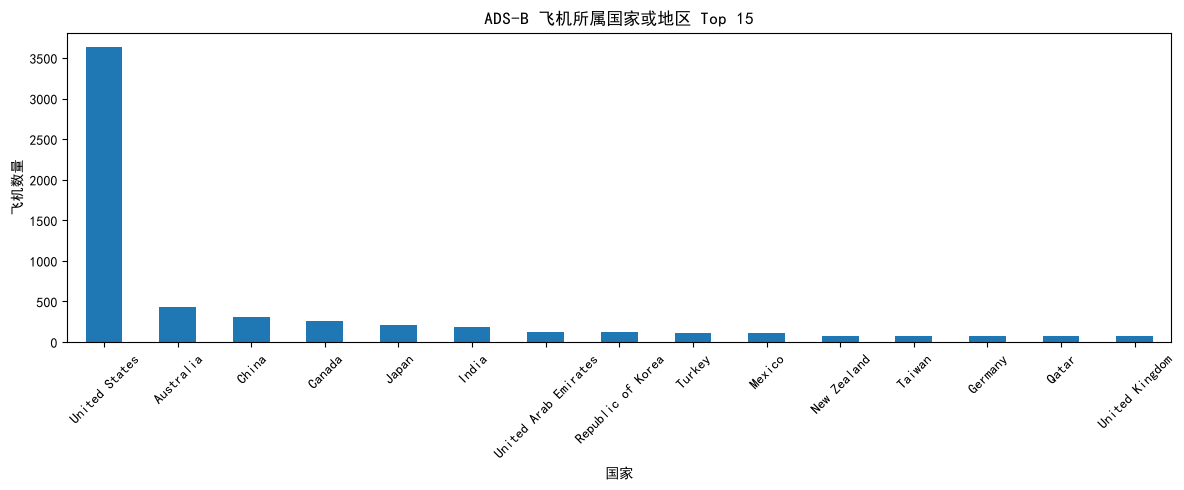

In [4]:
#飞机国籍可视化
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']   
plt.rcParams['axes.unicode_minus'] = False   
country_count.head(15).plot(kind="bar", figsize=(12, 5))

plt.title("ADS-B 飞机所属国家或地区 Top 15")
plt.xlabel("国家")
plt.ylabel("飞机数量")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

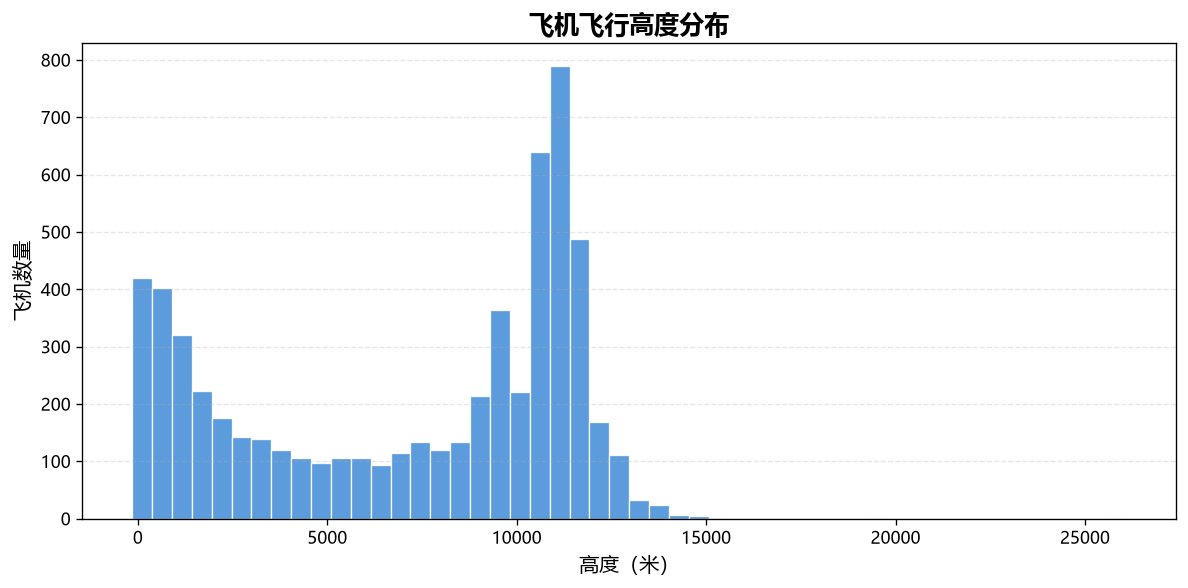

In [8]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.figure(figsize=(10, 5), dpi=120)

df_clean["altitude_m"].dropna().plot(
    kind="hist",
    bins=50,
    color="#4A90D9",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

plt.title("飞机飞行高度分布", fontsize=15, fontweight="bold")
plt.xlabel("高度（米）", fontsize=12)
plt.ylabel("飞机数量", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


In [29]:
print(df_clean["altitude_m"].describe())

count     6016.000000
mean      7084.782397
std       4362.678996
min       -152.400000
25%       2346.960000
50%       8900.160000
75%      10972.800000
max      26090.880000
Name: altitude_m, dtype: float64


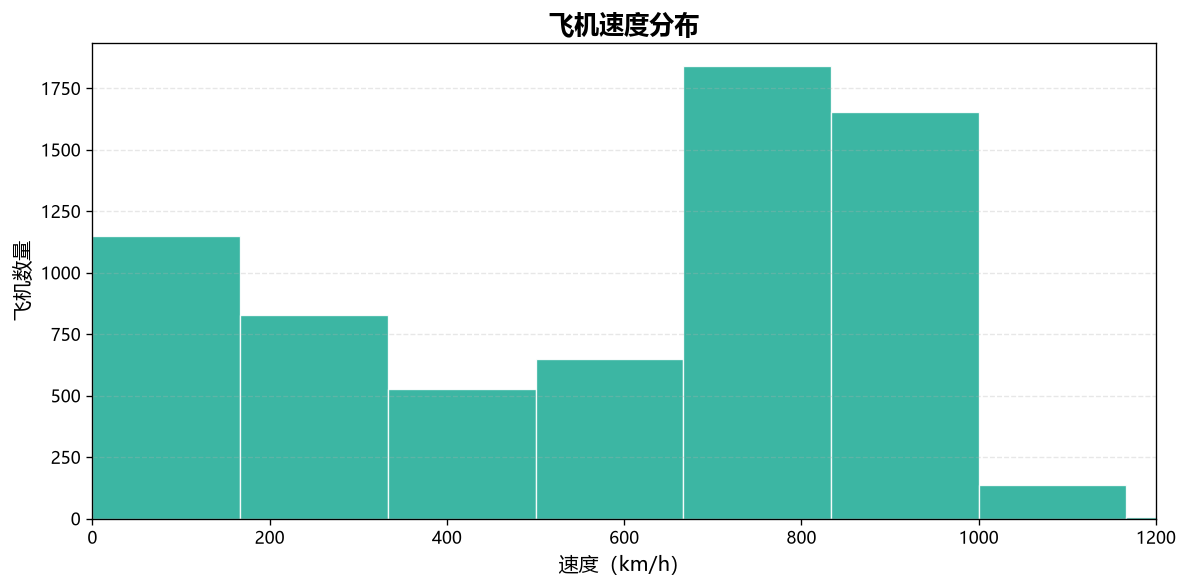

In [10]:
plt.figure(figsize=(10, 5), dpi=120)

df_clean["speed_kmh"].dropna().plot(
    kind="hist",
    bins=50,
    color="#27AE99",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

plt.title("飞机速度分布", fontsize=15, fontweight="bold")
plt.xlabel("速度（km/h）", fontsize=12)
plt.ylabel("飞机数量", fontsize=12)

plt.xlim(0, 1200)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

In [31]:
print(df_clean["speed_kmh"].describe())
#明显最高速度8332km/h不符合现实逻辑，在后续对异常数据进行处理

count    6797.000000
mean      577.594243
std       355.180611
min         0.000000
25%       257.436000
50%       707.976000
75%       839.952000
max      8332.488000
Name: speed_kmh, dtype: float64
